<a href="https://colab.research.google.com/github/encen-ya/PCVK_Genap2026/blob/main/Week9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>





# Langkah 1 – Siapkan Colab dan mount Drive



In [1]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


# Langkah 2 – Import library

In [2]:
import cv2
import numpy as np
from matplotlib import pyplot as plt

# Langkah 3 – Dilasi tanpa library morphology

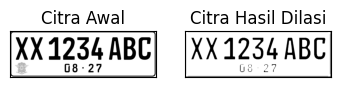

In [4]:
# Dilasi tanpa library
def dilasi_citra(F, w):
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)

    SED = np.ones((w, w), dtype=np.uint8)
    c = (w - 1) // 2

    for i in range(c, p - c):
        for j in range(c, q - c):
            temp = F[i-c:i+c+1, j-c:j+c+1]
            product = temp * SED
            imgD[i, j] = np.max(product)
    return imgD

img_d = cv2.imread('/content/drive/MyDrive/PCVK/Images/plat nomer.jpg', 0)
ret, thresh = cv2.threshold(img_d, 125, 200, cv2.THRESH_BINARY)

w = 5
imgD = dilasi_citra(thresh, w)

plt.subplot(131), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgD, cmap='gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()

# Langkah 4 – Dilasi dengan library OpenCV

[[1 1 1]
 [1 1 1]
 [1 1 1]]


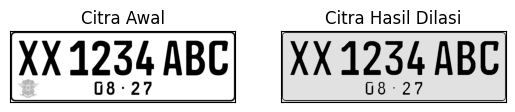

In [5]:
img = cv2.imread('/content/drive/MyDrive/PCVK/Images/plat nomer.jpg')
ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
kernel = np.ones((3, 3), np.uint8)   # uint8 agar kompatibel dengan OpenCV
dilasi = cv2.dilate(thresh, kernel, iterations=1)
print(kernel)

plt.subplot(121), plt.imshow(img), plt.title('Citra Awal')
plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(dilasi), plt.title('Citra Hasil Dilasi')
plt.xticks([]), plt.yticks([])
plt.show()

# Langkah 5 – Erosi tanpa library morphology (square 5 x 5)

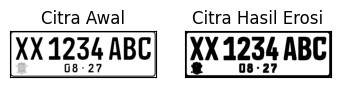

In [6]:
# Erosi tanpa library
def erosi_citra(F, k):
    m, n = F.shape
    SE = np.ones((k, k), dtype=np.uint8)
    c = (k - 1) // 2
    imgE = np.zeros((m, n), dtype=np.uint8)

    for i in range(c, m - c):
        for j in range(c, n - c):
            temp = F[i-c:i+c+1, j-c:j+c+1]
            product = temp * SE
            imgE[i, j] = np.min(product)
    return imgE

img_e = cv2.imread('/content/drive/MyDrive/PCVK/Images/plat nomer.jpg', 0)
ret1, thresh1 = cv2.threshold(img_e, 175, 225, cv2.THRESH_BINARY)

k = 5
imgE = erosi_citra(thresh1, k)

plt.subplot(131), plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgE, cmap='gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
plt.show()

# Langkah 6 – Erosi dengan library OpenCV (square 5 x 5)

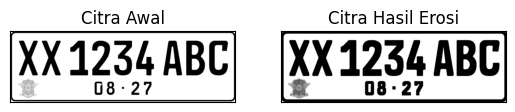

In [7]:
img = cv2.imread('/content/drive/MyDrive/PCVK/Images/plat nomer.jpg')

kernel = np.ones((5, 5), np.uint8)
erosion = cv2.erode(img, kernel, iterations=1)

plt.subplot(121), plt.imshow(img), plt.title('Citra Awal')
plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(erosion), plt.title('Citra Hasil Erosi')
plt.xticks([]), plt.yticks([])
plt.show()

# Langkah 7 – Opening (square 3 x 3), tanpa dan dengan library

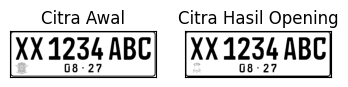

In [8]:
img_o = cv2.imread('/content/drive/MyDrive/PCVK/Images/plat nomer.jpg', 0)
reto, thresho = cv2.threshold(img_o, 127, 225, cv2.THRESH_BINARY)

k = 3
imgO = dilasi_citra(erosi_citra(thresho, k), k)

plt.subplot(131), plt.imshow(img_o, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgO, cmap='gray')
plt.title('Citra Hasil Opening'), plt.xticks([]), plt.yticks([])
plt.show()

### Dengan library:

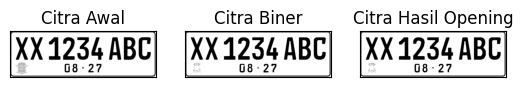

In [9]:
img = cv2.imread('/content/drive/MyDrive/PCVK/Images/plat nomer.jpg', 0)
ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
kernel = np.ones((3, 3), np.uint8)
openn = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel)

plt.subplot(131), plt.imshow(img, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(thresh, cmap='gray')
plt.title('Citra Biner'), plt.xticks([]), plt.yticks([])
plt.subplot(133), plt.imshow(openn, cmap='gray')
plt.title('Citra Hasil Opening'), plt.xticks([]), plt.yticks([])
plt.show()

# Langkah 8 – Closing (square 3 x 3), tanpa dan dengan library
### Tanpa library:

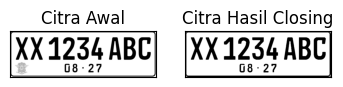

In [10]:
img_c = cv2.imread('/content/drive/MyDrive/PCVK/Images/plat nomer.jpg', 0)
retc, threshc = cv2.threshold(img_c, 127, 225, cv2.THRESH_BINARY)

k = 3
imgC = erosi_citra(dilasi_citra(threshc, k), k)

plt.subplot(131), plt.imshow(img_c, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgC, cmap='gray')
plt.title('Citra Hasil Closing'), plt.xticks([]), plt.yticks([])
plt.show()

### dengan library

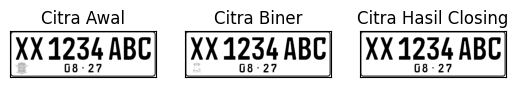

In [11]:
img = cv2.imread('/content/drive/MyDrive/PCVK/Images/plat nomer.jpg', 0)
ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
kernel = np.ones((3, 3), np.uint8)
closs = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel)

plt.subplot(131), plt.imshow(img, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(thresh, cmap='gray')
plt.title('Citra Biner'), plt.xticks([]), plt.yticks([])
plt.subplot(133), plt.imshow(closs, cmap='gray')
plt.title('Citra Hasil Closing'), plt.xticks([]), plt.yticks([])
plt.show()

# Langkah 9 – Dilasi dengan SE Cross 3 x 3 dan 5 x 5

SED = Cross 3


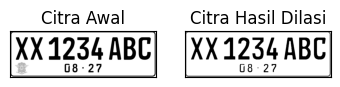

SED = Cross 5


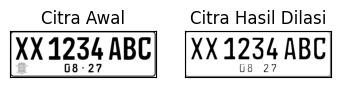

In [12]:
def dilasi_se(F, SED):
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)
    h, w = SED.shape
    ch, cw = (h - 1) // 2, (w - 1) // 2

    for i in range(ch, p - ch):
        for j in range(cw, q - cw):
            temp = F[i-ch:i+ch+1, j-cw:j+cw+1]
            imgD[i, j] = np.max(temp[SED == 1])
    return imgD

img_d = cv2.imread('/content/drive/MyDrive/PCVK/Images/plat nomer.jpg', 0)
ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)

# Cross 3 x 3
print('SED = Cross 3')
SED3 = np.array([[0, 1, 0],
                 [1, 1, 1],
                 [0, 1, 0]], dtype=np.uint8)
imgD = dilasi_se(thresh, SED3)

plt.subplot(131), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgD, cmap='gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()

# Cross 5 x 5
print('SED = Cross 5')
SED5 = np.array([[0, 0, 1, 0, 0],
                 [0, 0, 1, 0, 0],
                 [1, 1, 1, 1, 1],
                 [0, 0, 1, 0, 0],
                 [0, 0, 1, 0, 0]], dtype=np.uint8)
imgD = dilasi_se(thresh, SED5)

plt.subplot(131), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgD, cmap='gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()

# Langkah 10 – Dilasi dengan SE Circular 3 x 3 dan 5 x 5

SED = Circle 3


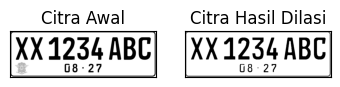

SED = Circle 5


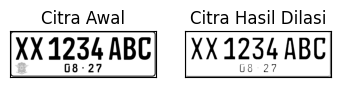

In [13]:
img_d = cv2.imread('/content/drive/MyDrive/PCVK/Images/plat nomer.jpg', 0)
ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)

for w in (3, 5):
    print('SED = Circle', w)
    SED = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (w, w))
    imgD = dilasi_se(thresh, SED)

    plt.subplot(131), plt.imshow(img_d, cmap='gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(132), plt.imshow(imgD, cmap='gray')
    plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
    plt.show()

# Langkah 11 – Erosi dengan SE Rectangle 3 x 5 dan 5 x 7

SE = Rectangle 3x5


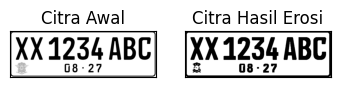

SE = Rectangle 5x7


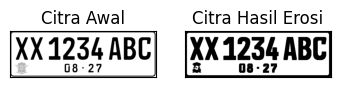

In [14]:
def erosi_se(F, SE):
    m, n = F.shape
    imgE = np.zeros((m, n), dtype=np.uint8)
    h, w = SE.shape
    ch, cw = (h - 1) // 2, (w - 1) // 2

    for i in range(ch, m - ch):
        for j in range(cw, n - cw):
            temp = F[i-ch:i+ch+1, j-cw:j+cw+1]
            imgE[i, j] = np.min(temp[SE == 1])
    return imgE

img_e = cv2.imread('/content/drive/MyDrive/PCVK/Images/plat nomer.jpg', 0)
ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)

# (lebar, tinggi) -> 5x3 dan 7x5
for (p, l, nama) in [(5, 3, 'Rectangle 3x5'), (7, 5, 'Rectangle 5x7')]:
    print('SE =', nama)
    SE = cv2.getStructuringElement(cv2.MORPH_RECT, (p, l))
    imgE = erosi_se(thresh1, SE)

    plt.subplot(131), plt.imshow(img_e, cmap='gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(132), plt.imshow(imgE, cmap='gray')
    plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
    plt.show()

# Langkah 12 – Erosi dengan SE Line Vertikal 3 dan 5

SE = Line Vertikal 3


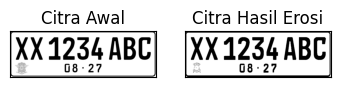

SE = Line Vertikal 5


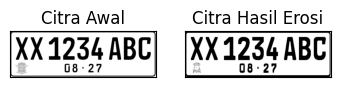

In [15]:
img_e = cv2.imread('/content/drive/MyDrive/PCVK/Images/plat nomer.jpg', 0)
# img_e = cv2.imread('/content/drive/MyDrive/PCVK/Images/j.png', 0)
ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)

for k in (3, 5):
    print('SE = Line Vertikal', k)
    SE = np.ones((k, 1), dtype=np.uint8)   # k baris, 1 kolom = garis vertikal
    imgE = erosi_se(thresh1, SE)

    plt.subplot(131), plt.imshow(img_e, cmap='gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(132), plt.imshow(imgE, cmap='gray')
    plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
    plt.show()

# Langkah 13 – Top Hat

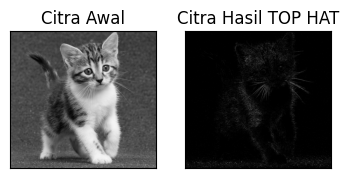

In [16]:
filterSize = (3, 3)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, filterSize)

img = cv2.imread('/content/drive/MyDrive/PCVK/Images/kitten01.jpg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

tophat_img = cv2.morphologyEx(img, cv2.MORPH_TOPHAT, kernel)

plt.subplot(131), plt.imshow(img, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(tophat_img, cmap='gray')
plt.title('Citra Hasil TOP HAT'), plt.xticks([]), plt.yticks([])
plt.show()

# Langkah 14 – Black Hat

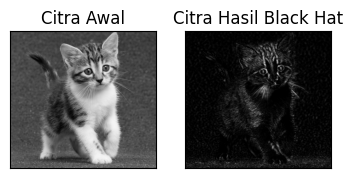

In [17]:
img = cv2.imread('/content/drive/MyDrive/PCVK/Images/kitten01.jpg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (13, 5))
blackhat = cv2.morphologyEx(img, cv2.MORPH_BLACKHAT, kernel)

plt.subplot(131), plt.imshow(img, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(blackhat, cmap='gray')
plt.title('Citra Hasil Black Hat'), plt.xticks([]), plt.yticks([])
plt.show()

# Langkah 15 – Skeleton

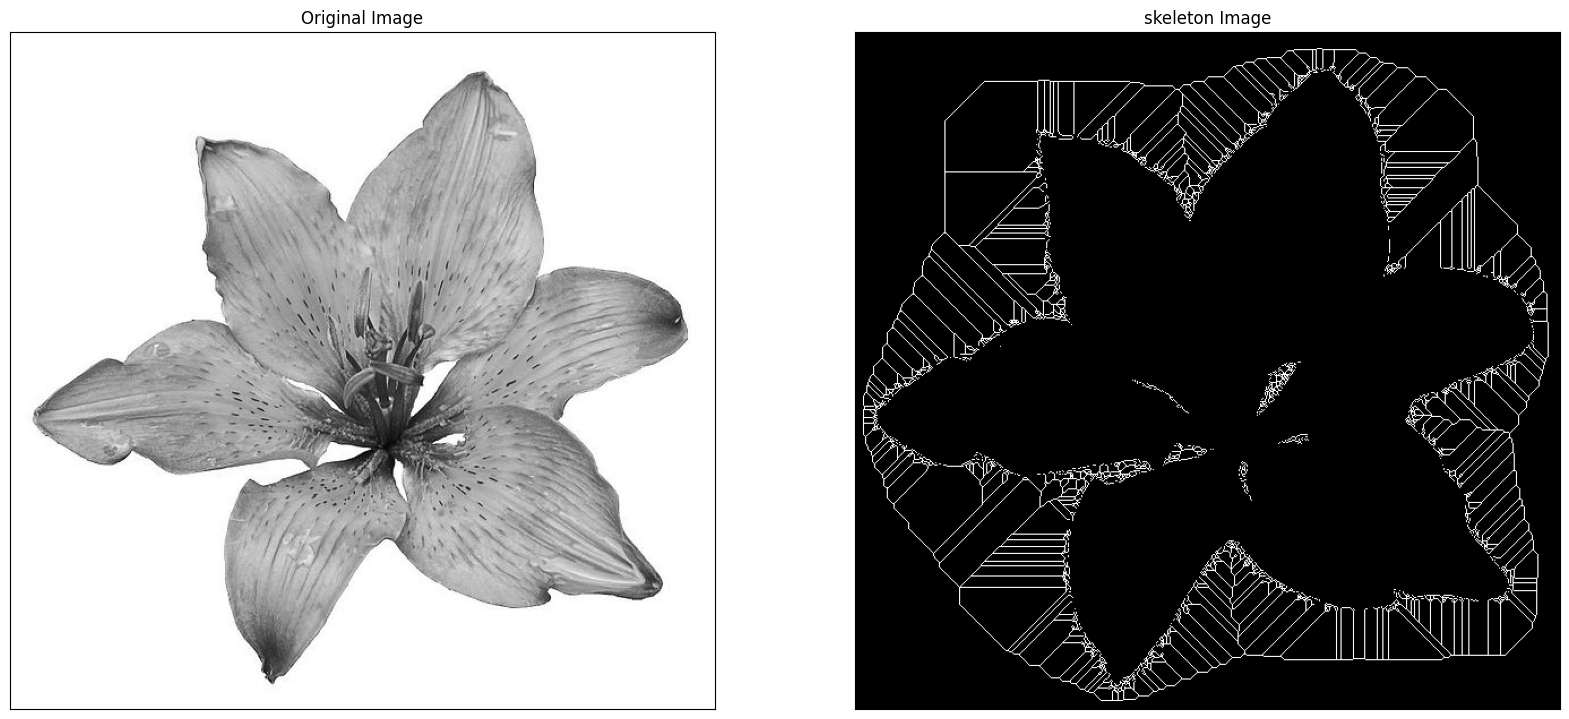

In [18]:
import cv2 as cv
from matplotlib import pyplot as plt
from skimage import filters
from skimage.morphology import skeletonize

img = cv.imread('/content/drive/MyDrive/PCVK/Images/lily.jpg', 0)

binary = img > filters.threshold_triangle(img)

# True/False menjadi 1/0
binary_cp = binary.copy()
binary_cp[binary_cp == True] = 1
binary_cp[binary_cp == False] = 0

skeleton = skeletonize(binary_cp)

plt.figure(figsize=(20, 20))
plt.subplot(121), plt.imshow(img, cmap='gray')
plt.title('Original Image'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(skeleton, cmap='gray')
plt.title('skeleton Image'), plt.xticks([]), plt.yticks([])
plt.savefig('binary and bin_skeleton.png')
plt.show()

# Langkah 16 – Skeleton Inverse

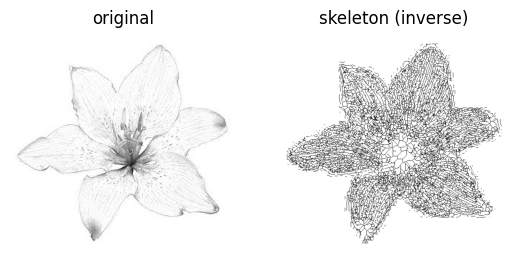

In [19]:
from skimage import io
from matplotlib import pyplot as plt
from skimage import filters
from skimage.morphology import skeletonize

img = io.imread('/content/drive/MyDrive/PCVK/Images/lily.jpg')[..., 0]

# bagian gelap dijadikan True, jadi pakai <
binary = img < filters.threshold_triangle(img)
skeleton = skeletonize(binary)

fig, ax = plt.subplots(1, 2)

ax[0].imshow(img, cmap='gray')
ax[0].set_title('original')
ax[0].set_axis_off()

# colormap dibalik: gray_r
ax[1].imshow(skeleton, cmap='gray_r')
ax[1].set_title('skeleton (inverse)')
ax[1].set_axis_off()
plt.show()

# Langkah 17 – Thickening (thinning)

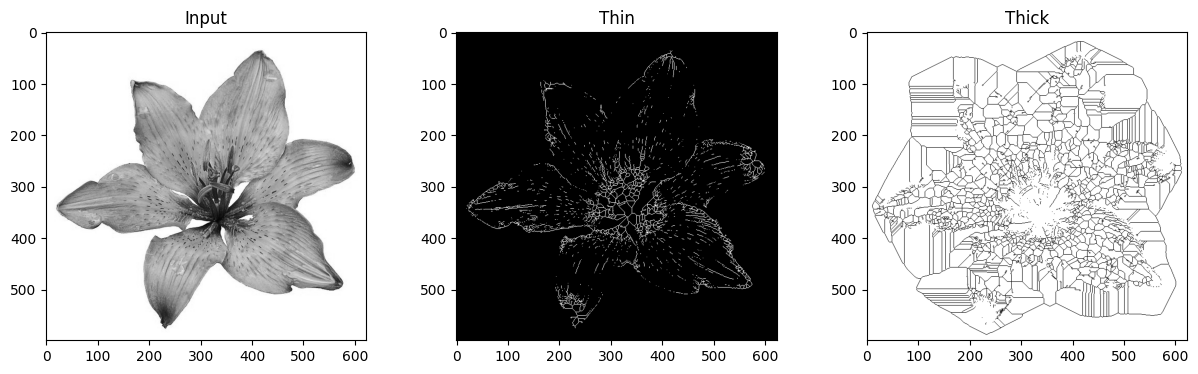

In [20]:
from skimage import img_as_float
from skimage import io, color, morphology
import matplotlib.pyplot as plt

image = img_as_float(color.rgb2gray(io.imread('/content/drive/MyDrive/PCVK/Images/lily.jpg')))
image_binary = image < 0.5

out_skeletonize = morphology.skeletonize(image_binary)
out_thin = morphology.thin(image_binary)
out_thick = ~morphology.thin(~image_binary)   # thickening

f, (ax0, ax1, ax2) = plt.subplots(1, 3, figsize=(15, 4))

ax0.imshow(image, cmap='gray')
ax0.set_title('Input')

ax1.imshow(out_thin, cmap='gray')
ax1.set_title('Thin')

ax2.imshow(out_thick, cmap='gray')
ax2.set_title('Thick')

plt.savefig('/tmp/char_out.png')
plt.show()

# Tugas E – Morfologi pada citra KTP

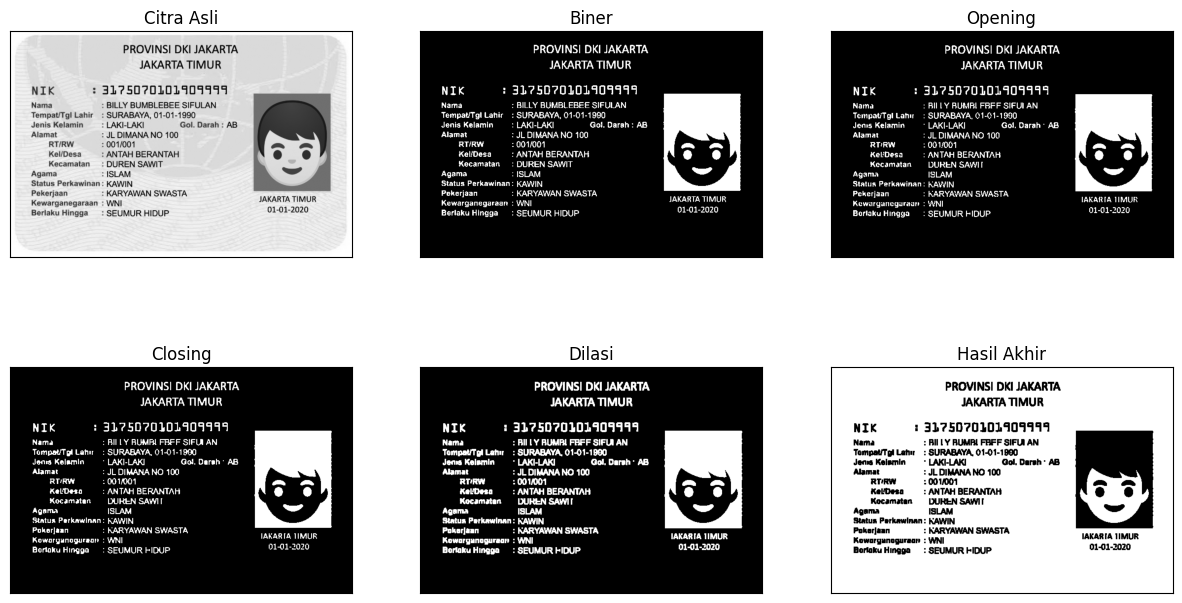

In [21]:
path_ktp = '/content/drive/MyDrive/PCVK/Images/ktp.jpg'   # ganti sesuai dataset Modul 7

img = cv2.imread(path_ktp)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# 1. Threshold (Otsu), teks dibuat putih di latar hitam
_, biner = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

# 2. Opening: hapus noise kecil
k_open = np.ones((2, 2), np.uint8)
opening = cv2.morphologyEx(biner, cv2.MORPH_OPEN, k_open)

# 3. Closing: sambung huruf yang terputus
k_close = np.ones((2, 2), np.uint8)
closing = cv2.morphologyEx(opening, cv2.MORPH_CLOSE, k_close)

# 4. Dilasi tipis: tebalkan goresan huruf
k_dil = np.ones((2, 2), np.uint8)
hasil = cv2.dilate(closing, k_dil, iterations=1)

# Kembalikan ke teks hitam di latar putih agar mudah dibaca
hasil_akhir = cv2.bitwise_not(hasil)

judul = ['Citra Asli', 'Biner', 'Opening', 'Closing', 'Dilasi', 'Hasil Akhir']
citra = [gray, biner, opening, closing, hasil, hasil_akhir]
plt.figure(figsize=(15, 8))
for i in range(6):
    plt.subplot(2, 3, i + 1), plt.imshow(citra[i], cmap='gray')
    plt.title(judul[i]), plt.xticks([]), plt.yticks([])
plt.show()